# Passaggio 3: archivio delle notizie, coppia MA-V (fonte: Alpaca)

**Obiettivo.** Controllare se le notizie di Alpaca (fonte Benzinga) sono utilizzabili per l'agente del Passaggio 5, e preparare per ogni segnale del Passaggio 4 l'elenco delle notizie uscite **prima** del segnale. Come nel Passaggio 4: solo la coppia MA-V e solo il periodo di addestramento (16 giugno - 16 settembre 2026). Il test non si usa.

**Prima di aprire il notebook** bisogna scaricare le notizie. Il notebook legge solo il file locale, così il risultato è sempre lo stesso (programma, Passaggio 3):
1. Creare un account Alpaca (basta Paper Trading, è gratuito), generare le chiavi API e copiare `.env.example` in `.env` inserendole. **Le chiavi non vanno mai in chat, nei notebook o nei commit.**
2. Dalla cartella del progetto, una chiamata di prova (non salva nulla): controlla che le chiavi funzionino e che lo storico di giugno-settembre sia accessibile col piano gratuito.
   ```bash
   uv run python -m src.news --probe
   ```
3. Se la prova va bene, scaricare tutto (crea `data/raw/news/alpaca/` con le risposte grezze e `data/processed/news_MA-V_train.parquet`):
   ```bash
   uv run python -m src.news
   ```

**Cosa fa il notebook**

| Parte | Cosa fa | Perché |
|---|---|---|
| 1 | Parametri | tutte le scelte in un posto solo |
| 2 | Caricamento di notizie e segnali | |
| 3 | Qualità delle notizie: quante, quando, su quali titoli | capire che cosa vedrà l'agente |
| 4 | Controllo degli orari | l'agente non deve vedere il futuro |
| 5 | Copertura: quanti segnali hanno una notizia prima | se quasi nessuno, questa fonte da sola non basta |
| 6 | Tabella notizie-segnali | input del Passaggio 5 |
| 7 | Esempi da leggere a mano | il gruppo deve guardare i dati, non solo i numeri |
| 8 | Conclusioni e cose aperte | |

Le scelte nostre sono segnate **[SCELTA]**, quelle aperte **[APERTO]**.

## 1. Parametri

In [1]:
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from pathlib import Path

PAIR = "MA-V"
TICKERS = ["MA", "V"]                                                       # ticker Alpaca dei due titoli
NEWS_PATH = Path("../data/processed/news_MA-V_train.parquet")               # creata da `python -m src.news`
SIGNALS_PATH = Path("../data/processed/signals_MA-V_train.csv")             # creata da segnale_mav.ipynb (Passaggio 4)
PRICES_PATH = Path("../data/processed/pairs_intraday/MA-V_1min.parquet")    # per scegliere gli orari casuali di confronto
OUT_LINK = Path("../data/processed/news_for_signals_MA-V_train.csv")        # input del Passaggio 5

TRAIN_END = "2026-09-16"           # ultimo giorno del train: il test (dal 17 settembre) non si usa
OPEN_SKIP, CLOSE_SKIP = 15, 30     # gli stessi del Passaggio 4: servono per scegliere orari "come quelli dei segnali"
WINDOWS_H = [2, 6, 24]             # [SCELTA] finestre di ricerca prima del segnale, in ore. Il programma lascia da decidere la lunghezza.
MAX_SYMBOLS_FOCUSED = 3            # [SCELTA] una notizia è "mirata" se cita al massimo 3 ticker. Oltre sono elenchi generici (es. "10 titoli da guardare")
N_PLACEBO_PER_SIGNAL = 50          # per ogni segnale, giorni di borsa casuali (alla stessa ora del giorno) per il confronto di copertura
SEED = 0

## 2. Caricamento

Si leggono le notizie scaricate e i 56 segnali del Passaggio 4. Orari di entrambi in **ora di New York, senza indicazione del fuso**, come i prezzi.

In [2]:
if not NEWS_PATH.exists():
    raise FileNotFoundError("Notizie non trovate: segui i tre passi all'inizio del notebook (account Alpaca, .env, `uv run python -m src.news`).")
if not SIGNALS_PATH.exists():
    raise FileNotFoundError("Segnali non trovati: esegui prima segnale_mav.ipynb (Passaggio 4).")

news = duckdb.sql(f"SELECT * FROM '{NEWS_PATH.as_posix()}'").df().sort_values("ts").reset_index(drop=True)
signals = pd.read_csv(SIGNALS_PATH, parse_dates=["t_signal", "t_entry", "t_exit"])

train_end = pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1)
assert news.ts.max() < train_end, "ci sono notizie dopo la fine del train: il test non si usa"
assert signals.t_exit.max() < train_end, "ci sono segnali nel periodo di test"
news["focused"] = news.n_symbols <= MAX_SYMBOLS_FOCUSED

print(f"notizie: {len(news):,}, dal {news.ts.min()} al {news.ts.max()}")
print(f"segnali: {len(signals)}, dal {signals.t_signal.min()} al {signals.t_signal.max()}")
news[["ts", "symbols", "headline", "source"]].head()

notizie: 174, dal 2026-06-01 09:53:25 al 2026-09-15 11:59:25
segnali: 56, dal 2026-06-16 13:00:00 al 2026-09-15 09:45:00


,ts,symbols,headline,source
0,2026-06-01 09:53:25,"BTC,BTCUSD,ETH,ETHUSD,MA,V,WU",Asian Emerging Markets Are Turning Stablecoins...,benzinga
1,2026-06-02 11:22:48,MA,Reported Earlier: MasterCard Announces Ling Ha...,benzinga
2,2026-06-02 13:29:23,"BLOK,ILF,NU,V",Why Is Nu Holdings Stock Falling Tuesday?,benzinga
3,2026-06-02 15:13:09,"DELL,GS,IBM,INTC,JPM,NVDA,V",Why Is IBM Up 30% In A Week? An Old Trump Clip...,benzinga
4,2026-06-03 06:14:38,"MA,PBEU,XLF,ZTR",Mastercard Names Asia-Pacific Chief Ling Hai A...,benzinga


## 3. Qualità delle notizie

Cosa vedrà l'agente: quante notizie ci sono, quando escono, se parlano davvero di MA e V o sono elenchi con tanti ticker, quali sono le fonti.

notizie al giorno: media 1.6, mediana 1, massimo 17; giorni (anche festivi) senza notizie: 48 su 108
notizie pubblicate a mercato aperto (lun-ven 9:30-16:00): 56%; nel weekend: 1%
mentions MA: 86, mentions V: 124, entrambi: 36
notizie mirate (al massimo 3 ticker): 57%; ticker per notizia: mediana 2, massimo 60

Fonti:
source
benzinga    174

Titoli duplicati (stesso titolo, id diversi): 7


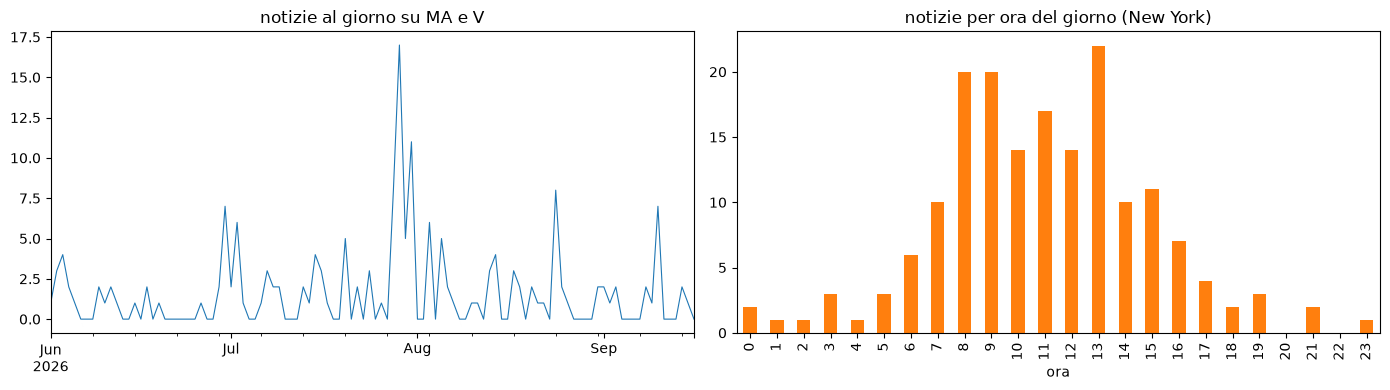

In [3]:
per_day = news.groupby(news.ts.dt.normalize()).size().reindex(pd.date_range(news.ts.min().normalize(), TRAIN_END), fill_value=0)
weekday = per_day.index.dayofweek < 5
mins = news.ts.dt.hour * 60 + news.ts.dt.minute
in_session = (news.ts.dt.dayofweek < 5) & (mins >= 9 * 60 + 30) & (mins < 16 * 60)

print(f"notizie al giorno: media {per_day.mean():.1f}, mediana {per_day.median():.0f}, massimo {per_day.max()}; giorni (anche festivi) senza notizie: {(per_day == 0).sum()} su {len(per_day)}")
print(f"notizie pubblicate a mercato aperto (lun-ven 9:30-16:00): {in_session.mean():.0%}; nel weekend: {(news.ts.dt.dayofweek >= 5).mean():.0%}")
print(f"mentions MA: {news.mentions_MA.sum()}, mentions V: {news.mentions_V.sum()}, entrambi: {(news.mentions_MA & news.mentions_V).sum()}")
print(f"notizie mirate (al massimo {MAX_SYMBOLS_FOCUSED} ticker): {news.focused.mean():.0%}; ticker per notizia: mediana {news.n_symbols.median():.0f}, massimo {news.n_symbols.max()}")
print("\nFonti:"); print(news.source.value_counts().head(8).to_string())
print(f"\nTitoli duplicati (stesso titolo, id diversi): {news.headline.duplicated().sum()}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
per_day.plot(ax=ax[0], lw=0.8); ax[0].set_title("notizie al giorno su MA e V")
news.groupby(news.ts.dt.hour).size().reindex(range(24), fill_value=0).plot.bar(ax=ax[1], color="tab:orange")
ax[1].set_title("notizie per ora del giorno (New York)"); ax[1].set_xlabel("ora")
plt.tight_layout(); plt.show()

**Lettura.** Numeri del train (16 giugno - 16 settembre, con le due settimane prima per la finestra all'indietro):
- **Le notizie sono poche**: 174 in 108 giorni di calendario, in media 1.6 al giorno (mediana 1, massimo 17 in un giorno). In 48 giorni su 108 non ce n'è nessuna (weekend e festivi inclusi; solo l'1% esce nel weekend).
- **Una sola fonte**: tutte da Benzinga.
- **Quasi metà sono poco utili**: solo il 57% cita al massimo 3 ticker; il resto sono elenchi (fino a 60 ticker in una notizia). Capita che una notizia su un altro titolo sia associata a V (per esempio una su IBM).
- **V è più coperta di MA** (124 notizie contro 86); 36 citano entrambe.
- **7 titoli duplicati**: la stessa vicenda in più articoli (per esempio la nomina del CFO di Mastercard, uno dei quali "Reported Earlier"). L'agente la vedrebbe due volte. **[APERTO]** raggruppare notizie con titoli molto simili.
- **Il 56% esce a mercato aperto**; le altre escono prima dell'apertura o dopo la chiusura e per i segnali del mattino sono già "vecchie" di diverse ore.
- **updated_at**: solo l'1% delle notizie viene aggiornato più di un'ora dopo la pubblicazione, e la mediana è zero. Il rischio è piccolo, ma teniamo `created_at` perché è la regola sicura.

## 4. Controllo degli orari: l'agente non deve vedere il futuro

Il Passaggio 3 del programma avverte: l'agente può leggere **solo** le notizie uscite prima del segnale. Tre controlli:

1. **Orario usato: `ts` = `created_at`**, la pubblicazione. `updated_at` (ultimo aggiornamento) non va usato: una notizia pubblicata prima del segnale ma corretta dopo avrebbe un testo "del futuro". Si misura quante notizie vengono aggiornate molto dopo.
2. **Regola di taglio: per un segnale alla barra *t* si usano solo notizie con `ts <= t`.** La barra *t* chiude un minuto dopo il suo orario, quindi la regola è prudente di circa un minuto: una notizia uscita proprio in quel minuto non si usa.
3. **Orario di pubblicazione vero.** Lo storico potrebbe essere stato caricato in ritardo, con orari non reali. Dai dati non si può controllare: **[APERTO]** il gruppo apre a mano i link di una decina di notizie, confronta l'orario con la pagina originale e scrive l'esito qui sotto.

In [4]:
lag = (news.updated_at_ny - news.ts).dt.total_seconds() / 3600
print(f"ore tra pubblicazione e ultimo aggiornamento: mediana {lag.median():.2f}, 90° percentile {lag.quantile(0.9):.1f}")
print(f"notizie aggiornate più di 1 ora dopo la pubblicazione: {(lag > 1).mean():.0%}  ->  per questo si usa created_at, non updated_at")

# 10 notizie a caso con link, da confrontare a mano con la pagina originale
news.sample(10, random_state=SEED).sort_values("ts")[["ts", "source", "headline", "url"]]

ore tra pubblicazione e ultimo aggiornamento: mediana 0.00, 90° percentile 0.0
notizie aggiornate più di 1 ora dopo la pubblicazione: 1%  ->  per questo si usa created_at, non updated_at


,ts,source,headline,url
7,2026-06-03 16:45:28,benzinga,If You Invested $100 In Mastercard Stock 15 Ye...,https://www.benzinga.com/insights/news/26/06/5...
54,2026-07-15 13:49:29,benzinga,"BMO Capital Maintains Outperform on Visa, Rais...",https://www.benzinga.com/news/26/07/60480230/b...
55,2026-07-16 10:31:55,benzinga,Visa Rolls Out Visa Stablecoin Platform For Fi...,https://www.benzinga.com/news/26/07/60499331/v...
63,2026-07-20 16:23:36,benzinga,Chamath Says Stripe's PayPal Deal Is 'a Shot A...,https://www.benzinga.com/markets/large-cap/26/...
89,2026-07-29 12:33:23,benzinga,"Visa Beats on Q3, Raises Revenue Outlook as An...",https://www.benzinga.com/analyst-stock-ratings...
101,2026-07-31 08:01:23,benzinga,"Keybanc Maintains Overweight on Mastercard, Ra...",https://www.benzinga.com/news/26/07/60833855/k...
122,2026-08-06 10:01:37,benzinga,Circle Price Targets Cut by Two Analysts—Here'...,https://www.benzinga.com/crypto/cryptocurrency...
130,2026-08-14 13:00:57,benzinga,"CNBC Halftime Report Final Trades: Visa, Unite...",https://www.benzinga.com/quote/LMT
147,2026-08-24 14:20:33,benzinga,Why Is Mastercard Stock Surging on Monday?,https://www.benzinga.com/trading-ideas/movers/...
156,2026-09-01 06:11:43,benzinga,Trump Accounts Get Major Corporate Boost: Amer...,https://www.benzinga.com/news/financing/26/09/...


## 5. Copertura: quanti segnali hanno una notizia prima?

Per ogni segnale si contano le notizie su MA o V uscite nelle ultime 2, 6 e 24 ore. Poi si confronta con **orari casuali**: per ogni segnale si prendono 50 giorni di borsa a caso del train e si guarda **la stessa ora del giorno** (un segnale delle 9:45 ha nelle ultime ore la notte, in cui escono poche notizie: confrontarlo con orari di tutta la giornata lo farebbe sembrare povero di notizie solo per l'ora): se i segnali non hanno più notizie del caso, l'agente non sta trovando "il motivo" del movimento, ma solo il rumore di fondo delle notizie.

Il programma avverte: *nessuna notizia trovata* non significa che non ne siano uscite, perché le fonti hanno copertura incompleta. Va scritto nel report.

In [5]:
def count_before(ts_sorted, when, hours):
    # quante notizie (di ts_sorted, ordinate) hanno ts nell'intervallo (when - hours, when]
    when = np.asarray(when, dtype="datetime64[ns]")
    lo = np.searchsorted(ts_sorted, when - np.timedelta64(int(hours * 3600), "s"), side="right")
    hi = np.searchsorted(ts_sorted, when, side="right")
    return hi - lo

subsets = {"qualsiasi": news, "mirate": news[news.focused], "su MA": news[news.mentions_MA], "su V": news[news.mentions_V]}
arrays = {k: v.ts.to_numpy(dtype="datetime64[ns]") for k, v in subsets.items()}

# orari casuali: per ogni segnale, N_PLACEBO_PER_SIGNAL giorni di borsa casuali del train, alla stessa ora del giorno del segnale
days = np.array(pd.to_datetime(duckdb.sql(f"SELECT DISTINCT CAST(ts AS DATE) AS d FROM '{PRICES_PATH.as_posix()}' WHERE ts < '{train_end}' ORDER BY d").df().d), dtype="datetime64[ns]")
tod = (signals.t_signal - signals.t_signal.dt.normalize()).to_numpy()
placebo = (np.random.default_rng(SEED).choice(days, size=(len(signals), N_PLACEBO_PER_SIGNAL)) + tod[:, None]).ravel()

rows = []
for h in WINDOWS_H:
    for name, arr in arrays.items():
        s = count_before(arr, signals.t_signal.to_numpy(dtype="datetime64[ns]"), h)
        p = count_before(arr, placebo, h)
        rows.append(dict(finestra_ore=h, notizie=name, segnali_con_notizia=(s > 0).mean(), orari_casuali_con_notizia=(p > 0).mean(),
                         notizie_per_segnale=s.mean(), notizie_per_orario_casuale=p.mean()))
coverage = pd.DataFrame(rows)
coverage.round(2).style.format({"segnali_con_notizia": "{:.0%}", "orari_casuali_con_notizia": "{:.0%}"})

,finestra_ore,notizie,segnali_con_notizia,orari_casuali_con_notizia,notizie_per_segnale,notizie_per_orario_casuale
0,2,qualsiasi,25%,27%,0.390000,0.450000
1,2,mirate,14%,18%,0.210000,0.310000
2,2,su MA,18%,18%,0.200000,0.220000
3,2,su V,18%,20%,0.300000,0.280000
4,6,qualsiasi,43%,43%,0.880000,0.890000
5,6,mirate,27%,27%,0.570000,0.590000
6,6,su MA,29%,27%,0.380000,0.410000
7,6,su V,34%,36%,0.680000,0.600000
8,24,qualsiasi,82%,75%,2.320000,2.100000
9,24,mirate,59%,55%,1.320000,1.240000


**Lettura.**

| Finestra prima del segnale | Segnali con almeno una notizia (qualsiasi) | di cui con una notizia mirata | Orari casuali (qualsiasi) | Orari casuali (mirate) |
|---|---|---|---|---|
| 2 ore | 25% | 14% | 27% | 18% |
| 6 ore | 43% | 27% | 43% | 27% |
| 24 ore | 82% | 59% | 75% | 55% |

- **I segnali hanno più o meno le stesse notizie degli orari casuali alla stessa ora del giorno** (a 6 ore 43% contro 43%; a 2 ore 25% contro 27%; a 24 ore 82% contro 75%). Con soli 56 segnali queste differenze non sono significative (l'errore standard su una quota del 25% è circa 6 punti percentuali). Il punto è che **non vediamo nessuna prova che gli allargamenti dello spread coincidano con una notizia**: l'ipotesi del progetto (allargamenti per rumore rientrano, quelli per un fatto no) non emerge da questi dati.
- **Con finestre corte la maggior parte dei segnali non ha nessuna notizia**: circa 3 su 4 a 2 ore (6 su 7 se contiamo solo le mirate). In quei casi l'agente darebbe la risposta di default (si entra scommettendo sul rientro), cioè farebbe quello che fa già la versione A.
- **A 24 ore la copertura sale all'82%, ma** include notizie uscite anche 20 ore prima, difficilmente collegate a un movimento di pochi minuti dello spread. Una copertura alta a 24 ore non vuol dire che l'agente trovi la causa del segnale.

## 6. La tabella notizie-segnali (input del Passaggio 5)

Per ogni segnale si salvano tutte le notizie delle ultime 24 ore (la finestra più lunga provata), con quanti minuti prima del segnale sono uscite. L'agente potrà poi usare solo le ultime 2 o 6 ore filtrando per `minutes_before`: la finestra è una delle opzioni da confrontare nel Passaggio 5.

Si salvano anche le notizie *non mirate* (con molti ticker), segnate con `focused = False`: l'agente o il filtro decidono se usarle.

In [6]:
max_h = max(WINDOWS_H)
rows = []
for sid, sig in signals.iterrows():
    w = news[(news.ts <= sig.t_signal) & (news.ts > sig.t_signal - pd.Timedelta(hours=max_h))]
    for _, n in w.iterrows():
        rows.append(dict(signal_id=sid, t_signal=sig.t_signal, direction=sig.direction, leg_piu_mosso=sig.leg_piu_mosso, news_id=n.id, news_ts=n.ts,
                         minutes_before=(sig.t_signal - n.ts).total_seconds() / 60, headline=n.headline, summary=n.summary, source=n.source,
                         symbols=n.symbols, n_symbols=n.n_symbols, focused=n.focused, mentions_MA=n.mentions_MA, mentions_V=n.mentions_V, url=n.url))
link = pd.DataFrame(rows)
assert (link.news_ts <= link.t_signal).all(), "una notizia è successiva al segnale"

OUT_LINK.parent.mkdir(parents=True, exist_ok=True)
link.to_csv(OUT_LINK, index=False)
print(f"{len(link)} coppie (segnale, notizia) per {link.signal_id.nunique()} segnali su {len(signals)} (gli altri non hanno nessuna notizia nelle ultime {max_h} ore)")
print(f"salvato in {OUT_LINK}")
link.head()

130 coppie (segnale, notizia) per 46 segnali su 56 (gli altri non hanno nessuna notizia nelle ultime 24 ore)
salvato in ../data/processed/news_for_signals_MA-V_train.csv


,signal_id,t_signal,direction,leg_piu_mosso,news_id,news_ts,minutes_before,headline,summary,source,symbols,n_symbols,focused,mentions_MA,mentions_V,url
0,0,2026-06-16 13:00:00,long MA / short V,V,53213905,2026-06-15 19:49:51,1030.150000,Travala Wants To Be The Travel Infrastructure ...,It was probably only a matter of time before c...,benzinga,"AVA,AVAUSD,BKNG,BNBTUSD,BTC,BTCUSD,CRCL,CROUSD...",11,False,False,True,https://www.benzinga.com/Opinion/26/06/5321390...
1,2,2026-06-17 15:29:00,long MA / short V,MA,53252937,2026-06-17 11:00:30,268.500000,Illinois Rep. Jonathan Jackson Sold Up to $50K...,,benzinga,"MSFT,SPG,V",3,True,False,True,https://www.benzinga.com/insights/government/2...
2,3,2026-06-18 09:45:00,long MA / short V,MA,53252937,2026-06-17 11:00:30,1364.500000,Illinois Rep. Jonathan Jackson Sold Up to $50K...,,benzinga,"MSFT,SPG,V",3,True,False,True,https://www.benzinga.com/insights/government/2...
3,3,2026-06-18 09:45:00,long MA / short V,MA,53262117,2026-06-17 15:31:48,1093.200000,Wall Street Wants To Tokenize Everything—But I...,"Wall Street is racing to tokenize stocks, but ...",benzinga,"BLK,COIN,GS,HOOD,JPM,MA,V",7,False,True,True,https://www.benzinga.com/markets/prediction-ma...
4,8,2026-07-01 09:45:00,short MA / long V,V,60187017,2026-06-30 09:57:07,1427.883333,"'Visa, Stripe Among Firms Joining Forces on Ma...",,benzinga,"BLK,BNY,COIN,GOOG,GOOGL,KLAR,V",7,False,False,True,https://www.benzinga.com/news/26/06/60187017/v...


## 7. Esempi da leggere a mano

Per qualche segnale si leggono i titoli delle ultime 6 ore, come li vedrebbe l'agente. Serve a capire a occhio se le notizie c'entrano col movimento dello spread, e sarà la base per classificare a mano 30-50 segnali (programma, Passaggio 5).

In [7]:
shown = 0
for sid, sig in signals.iterrows():
    w = link[(link.signal_id == sid) & (link.minutes_before <= 6 * 60)].sort_values("minutes_before")
    if len(w) == 0:
        continue
    print(f"\n=== segnale {sid}: {sig.t_signal}, {sig.direction}, si è mosso di più {sig.leg_piu_mosso}, risultato lordo {sig.gross_bps:.0f} bps ===")
    for _, n in w.head(5).iterrows():
        print(f"  -{n.minutes_before:5.0f} min [{n.symbols}] {n.headline[:110]}")
    shown += 1
    if shown >= 8:
        break
if shown == 0:
    print("nessun segnale ha notizie nelle ultime 6 ore")


=== segnale 2: 2026-06-17 15:29:00, long MA / short V, si è mosso di più MA, risultato lordo -4 bps ===
  -  268 min [MSFT,SPG,V] Illinois Rep. Jonathan Jackson Sold Up to $50K Worth of Microsoft Stock

=== segnale 9: 2026-07-02 09:52:00, long MA / short V, si è mosso di più MA, risultato lordo 30 bps ===
  -   25 min [MA,VEON] Veon Launches Digital Finance Push With Mastercard
  -  178 min [V] Visa Announced Execution Of Live Agentic Commerce Transactions Across Europe With AI Agents Carrying Out Purch
  -  227 min [MA,VEON] VEON Partners With Mastercard To Expand Financial Services Across Ukraine, Kazakhstan, Pakistan and Uzbekistan
  -  242 min [BTCUSD,MA,V,ZECUSD] Crypto Card Deposits Top $10 Billion as Stablecoin Payment Rails See Rapid Adoption
  -  303 min [V] Visa Pay Expands Across Africa And Central Asia With SDK For Faster Virtual Card And Payment Deployment

=== segnale 11: 2026-07-07 09:45:00, short MA / long V, si è mosso di più V, risultato lordo -46 bps ===
  -  151 mi

## 8. Conclusioni e cose aperte

I numeri sono quelli dell'esecuzione sul train e sulle 174 notizie scaricate il 6 novembre 2026. Se si scaricano di nuovo le notizie o si cambiano i parametri, vanno riaggiornati.

### Cosa abbiamo trovato
1. **L'API di Alpaca funziona** e lo storico di giugno-settembre 2026 è accessibile col piano gratuito (prova con `--probe`). Orari in UTC, convertiti a New York; `updated_at` quasi sempre uguale a `created_at`.
2. **Le notizie sono poche**: 174 su MA e V in 3.5 mesi (1.6 al giorno), una sola fonte (Benzinga), il 57% mirate, 7 duplicati.
3. **I segnali non coincidono con le notizie**: la quota di segnali con una notizia nelle ultime 2, 6 e 24 ore (25%, 43%, 82%) è simile a quella degli orari casuali alla stessa ora del giorno (27%, 43%, 75%).
4. **130 coppie segnale-notizia per 46 segnali su 56** nelle ultime 24 ore, salvate in `data/processed/news_for_signals_MA-V_train.csv`. Per i restanti 10 segnali non c'è nessuna notizia. Con la sola finestra delle ultime 2 ore i segnali con almeno una notizia sono circa 14 (circa 8 se mirate).
5. **Esempi letti a mano (parte 7)**: le notizie presenti sono soprattutto cambi di target price degli analisti sui due titoli insieme (segnali 11 e 22: per il programma è rumore, quindi si entra), annunci di prodotto (Visa Stablecoin, accordo VEON-Mastercard) e articoli con molti ticker. Nei primi esempi c'è un solo caso che somiglia a un fatto strutturale su un solo titolo: il taglio del 7% della forza lavoro di Visa (Bloomberg), 65 minuti prima del segnale 23, chiuso a +26 bps lordi. Un singolo caso non dice niente sul valore dell'agente.

### Cosa significa per l'agente (Passaggio 5)
- **Il confronto A, B, C avrà pochissimi segnali su cui differire.** Con finestra di 2-6 ore l'agente ha almeno una notizia per circa 14-24 segnali su 56 (8-15 se solo mirate); per tutti gli altri B e C coincidono con A. Una differenza di risultato calcolata su 8-24 trade non si distingue dal caso. Il test serve a far funzionare la pipeline e misurare la copertura, non a dire quale versione è migliore.
- **Rischio da dichiarare nel report**: la copertura incompleta delle notizie (una fonte, 1.6 al giorno) significa che "nessuna notizia trovata" non vuol dire "non è successo niente".

### Cose aperte
1. **Orario vero di pubblicazione.** Non si può controllare dai dati: il gruppo apre a mano i link della tabella della parte 4 (10 notizie a caso), confronta l'orario con la pagina Benzinga e scrive qui l'esito.
2. **Più segnali e più notizie.** Opzioni, da decidere insieme: (a) estendere il Passaggio 4 e le notizie alle altre 9 coppie (più segnali e più notizie, ma serve un'altra scelta dei parametri); (b) aggiungere una seconda fonte (GDELT, archivio Bloomberg) per aumentare la copertura; (c) abbassare la soglia di ingresso (1.5 dà circa 116 trade, ma guadagno medio più basso).
3. **Duplicati e notizie non mirate**: raggruppare i titoli simili e decidere se l'agente vede anche le notizie con molti ticker.
4. **Finestra di ricerca**: 2, 6 o 24 ore. Il programma lascia da decidere la lunghezza; qui conviene partire da 6 ore (copertura 43%, ancora legata al movimento) e confrontare.
5. **Classificazione a mano** di 30-50 segnali con le notizie della tabella: il programma la chiede per misurare l'accordo con l'agente. Con 56 segnali sono quasi tutti, ma solo i 46 con una notizia nelle 24 ore hanno qualcosa da classificare.
6. **docs/Programma.md**: aggiornare il Passaggio 3 con quanto fatto qui, da concordare nel gruppo.

### Limiti da dichiarare nel report
- Una sola fonte, copertura incompleta.
- Una sola coppia e 64 giorni: pochi segnali e pochissimi con una notizia.
- Notizie associate ai ticker da Benzinga: una notizia taggata MA non è per forza su Mastercard.
- Orari non verificati a mano (fino a quando il gruppo non lo fa).
- Solo titolo e sommario, non il testo completo.